In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

In [42]:
df = pd.read_csv('form_responses.csv')
df.sort_values(by='Timestamp', inplace=True)

# Cleaning

Situazione iniziale

In [43]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 150 entries, 100 to 101
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Timestamp           150 non-null    object 
 1   age                 150 non-null    int64  
 2   sex                 150 non-null    object 
 3   weight              150 non-null    float64
 4   height              150 non-null    int64  
 5   train_years         150 non-null    object 
 6   train_week          150 non-null    int64  
 7   z2_train_week       148 non-null    float64
 8   fartelk_train_week  136 non-null    float64
 9   power_train_week    118 non-null    float64
 10  avg_km_week         150 non-null    object 
 11  sleep_hour          150 non-null    int64  
 12  vo2_max             150 non-null    object 
 13  min_heart_rate      150 non-null    int64  
 14  max_heart_rate      150 non-null    int64  
 15  cadence             141 non-null    object 
 16  hm_time    

In [44]:
print(f"Numero di righe: {df.shape[0]}")
print(f"Numero di colonne: {df.shape[1]}")

Numero di righe: 150
Numero di colonne: 18


In [45]:
df.head()

,Timestamp,age,sex,weight,height,train_years,train_week,z2_train_week,fartelk_train_week,power_train_week,avg_km_week,sleep_hour,vo2_max,min_heart_rate,max_heart_rate,cadence,hm_time,mid_hm_time
100,01/07/2025 00:07:41,18,Maschio,83.0,187,6,4,1.0,2.0,1.0,30,9,59,59,180,175,1:40:32,00:46:57
99,01/07/2025 00:41:15,27,Maschio,68.0,170,2,6,2.0,2.0,3.0,70,6,63,53,191,180,1:22:47,37:30
98,01/07/2025 08:48:29,23,Maschio,77.0,181,1,2,1.0,1.0,2.0,25,6,50,45,196,165,1:52:00,00:55:00
97,01/07/2025 10:11:15,28,Maschio,75.0,176,2,3,2.0,1.0,2.0,20,7,49,50,196,165,01:39:57,00:49:44
96,01/07/2025 11:59:10,27,Maschio,99.0,188,1,3,1.0,1.0,1.0,10,8,40,69,190,152,2:35:00,1:10:00


In [46]:
df.drop(columns=['Timestamp'], inplace=True)

In [47]:
df['sex'] = df['sex'].replace({'Femmina': 0, 'Maschio': 1})
df['sex'] = df['sex'].astype(int)

C:\Users\Gabri\AppData\Local\Temp\ipykernel_2912\160705813.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['sex'] = df['sex'].replace({'Femmina': 0, 'Maschio': 1})


In [48]:
df.train_years = df['train_years'].replace({'Meno di 1': 0.5 , '10 in su': 11})
df['train_years'] = df['train_years'].astype(int)

In [49]:
df.z2_train_week = df.z2_train_week.fillna(0).astype(int)
df.fartelk_train_week = df.fartelk_train_week.fillna(0).astype(int)
df.power_train_week = df.power_train_week.fillna(0).astype(int)

In [50]:
df['avg_km_week'] = df['avg_km_week'].replace({'Più di 80': 85})
df['avg_km_week'] = df['avg_km_week'].astype(int)

Creo la colonna per avere i tempi in secondi

In [51]:
def time_to_seconds(t):
    parts = t.split(':')
    parts = [int(p) for p in parts]
    if len(parts) == 3:
        h, m, s = parts
    elif len(parts) == 2:
        h = 0
        m, s = parts
    else:
        return None
    return h * 3600 + m * 60 + s

# Applica la funzione
df['hm_time_sec'] = df['hm_time'].apply(time_to_seconds)
df['mid_hm_time_sec'] = df['mid_hm_time'].apply(time_to_seconds)

Creo la colonna per avere i tempi in minuti

In [52]:
def time_to_minutes(t):
    parts = t.split(':')
    parts = [int(p) for p in parts]
    if len(parts) == 3:
        h, m, s = parts
    elif len(parts) == 2:
        h = 0
        m, s = parts
    else:
        return None
    return h * 60 + m + s / 60

df['hm_time_min'] = df['hm_time'].apply(time_to_minutes)
df['mid_hm_time_min'] = df['mid_hm_time'].apply(time_to_minutes)

df.drop(columns=['hm_time', 'mid_hm_time'], inplace=True)


Elimino outlier troppo grandi

In [53]:
df = df[df['hm_time_min'] < 140]

Colonne con troppi valori null

In [54]:
df.drop(columns=['cadence', 'vo2_max'], inplace=True)

Controlliamo se ci sono valori null nel dataframe

In [55]:
df.isnull().values.any()

np.False_

Stampiamo i risultati della fase di cleaning

In [56]:
print(f"Numero di righe nel DataFrame: {len(df)}")
print(f"Numero di colonne nel DataFrame: {len(df.columns)}")

Numero di righe nel DataFrame: 145
Numero di colonne nel DataFrame: 17


**Controllo finale** 

In [57]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 145 entries, 100 to 102
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   age                 145 non-null    int64  
 1   sex                 145 non-null    int64  
 2   weight              145 non-null    float64
 3   height              145 non-null    int64  
 4   train_years         145 non-null    int64  
 5   train_week          145 non-null    int64  
 6   z2_train_week       145 non-null    int64  
 7   fartelk_train_week  145 non-null    int64  
 8   power_train_week    145 non-null    int64  
 9   avg_km_week         145 non-null    int64  
 10  sleep_hour          145 non-null    int64  
 11  min_heart_rate      145 non-null    int64  
 12  max_heart_rate      145 non-null    int64  
 13  hm_time_sec         145 non-null    int64  
 14  mid_hm_time_sec     145 non-null    int64  
 15  hm_time_min         145 non-null    float64
 16  mid_hm_time

---

# EDA

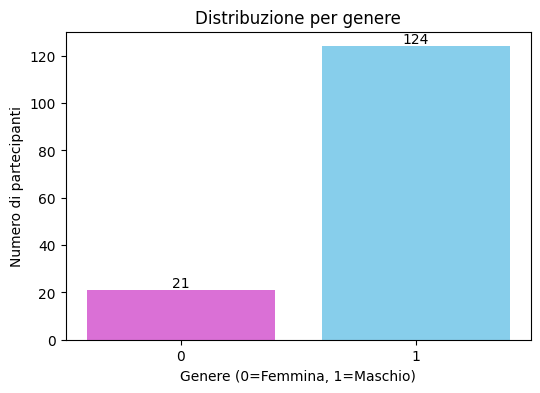

In [58]:
gender_counts = df['sex'].value_counts().sort_index()
plt.figure(figsize=(6, 4))
bars = plt.bar(gender_counts.index.astype(str), gender_counts.values, color=['orchid', 'skyblue'])
plt.xlabel('Genere (0=Femmina, 1=Maschio)')
plt.ylabel('Numero di partecipanti')
plt.title('Distribuzione per genere')

for bar in bars:
     height = bar.get_height()
     plt.text(bar.get_x() + bar.get_width() / 2, height, f'{int(height)}', ha='center', va='bottom')

plt.show()


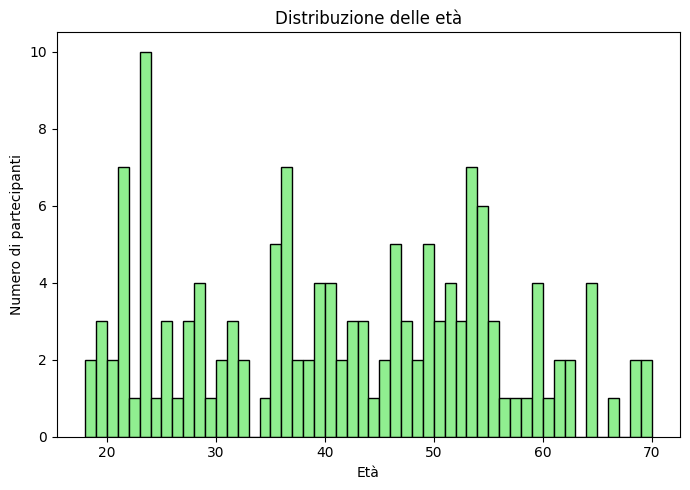

Età media: 41.57931034482758


In [59]:
fig, ax = plt.subplots(figsize=(7, 5))

ax.hist(df['age'], bins=range(df['age'].min(), df['age'].max()), color='lightgreen', edgecolor='black')
ax.set_xlabel('Età')
ax.set_ylabel('Numero di partecipanti')
ax.set_title('Distribuzione delle età')

plt.tight_layout()
plt.show()

print("Età media:", df['age'].mean())


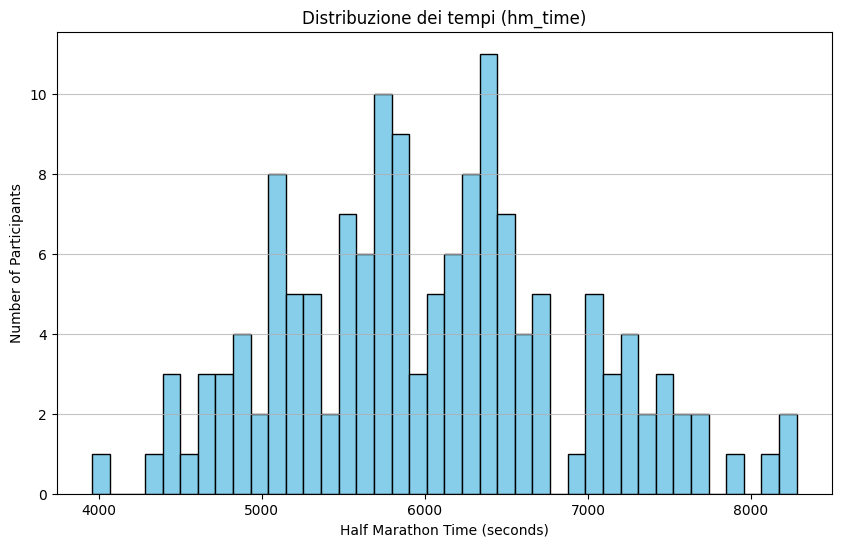

In [60]:
hm_time_sec = df['hm_time_sec']
plt.figure(figsize=(10, 6))
plt.hist(hm_time_sec, bins=40, color='skyblue', edgecolor='black')
plt.xlabel('Half Marathon Time (seconds)')
plt.ylabel('Number of Participants')
plt.title('Distribuzione dei tempi (hm_time)')
plt.grid(axis='y', alpha=0.75)
plt.show()

Possiamo notare che la distribuzione dei tempi segue una distribuzione normale.

In [61]:
print("Tempo medio (min):", df.hm_time_min.mean())
print("Deviazione standard (min):", df.hm_time_min.std())

Tempo medio (min): 100.49827586206897
Deviazione standard (min): 14.75482288332982


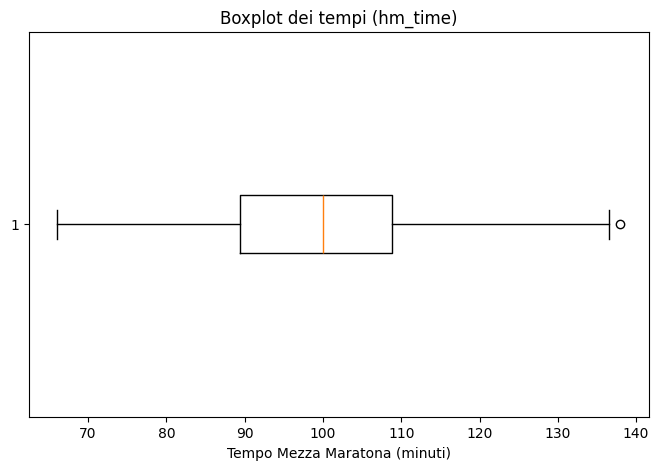

In [62]:
plt.figure(figsize=(8, 5))
plt.boxplot(df.hm_time_min, vert=False)
plt.xlabel('Tempo Mezza Maratona (minuti)')
plt.title('Boxplot dei tempi (hm_time)')
plt.show()

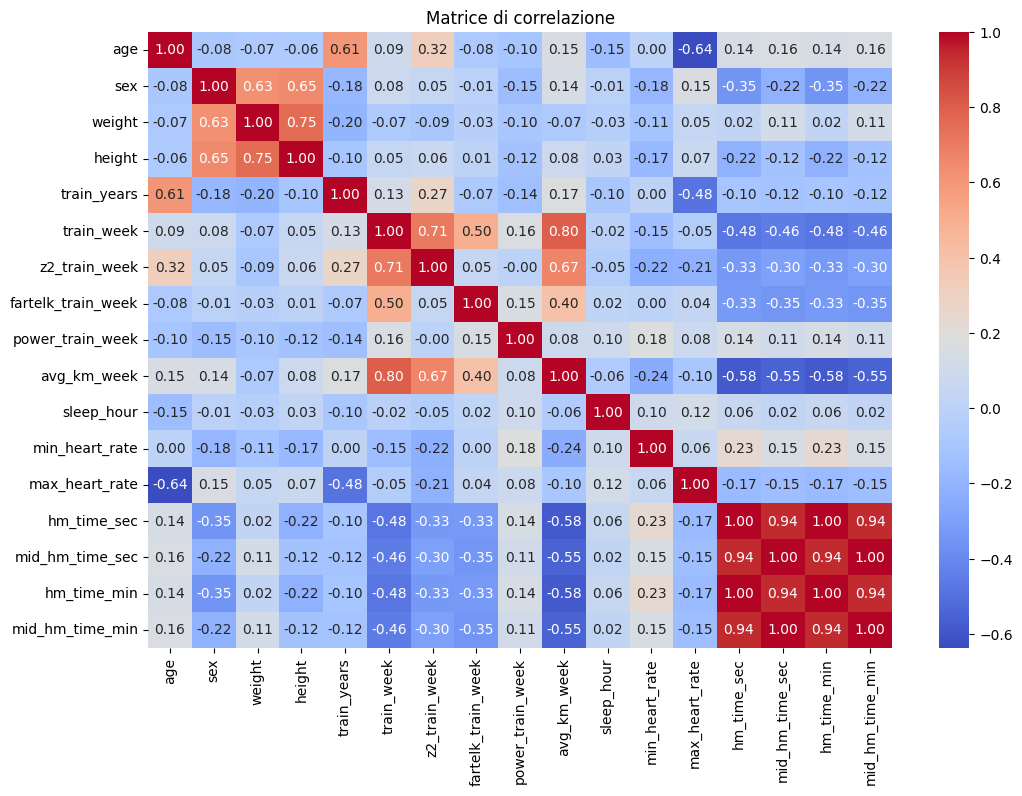

In [63]:

plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm", xticklabels=True, yticklabels=True)
plt.title("Matrice di correlazione")
plt.show()


Dalla matrice di correlazione emerge che i fattori più associati alla performance sono il chilometraggio medio settimanale e la frequenza degli allenamenti, oltre anche gli anni di esperienza. Le variabili fisiologiche, invece,  hanno correlazioni più deboli sul tempo finale.

### Z2 vs Power

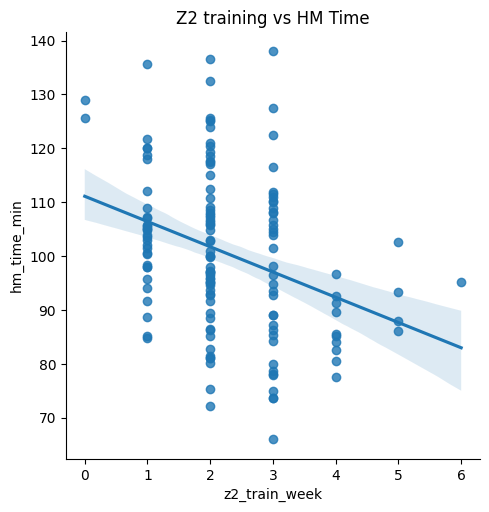

In [64]:
# Scatter plot + regressione
sns.lmplot(data=df, x='z2_train_week', y='hm_time_min')
plt.title("Z2 training vs HM Time")
plt.show()

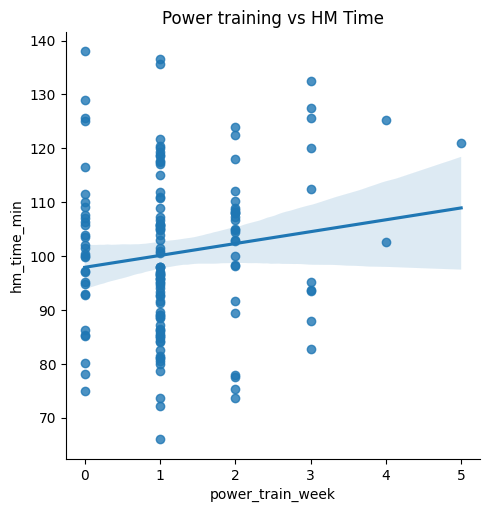

In [65]:
sns.lmplot(data=df, x='power_train_week', y='hm_time_min')
plt.title("Power training vs HM Time")
plt.show()

L'**indice di Pearson** permette di capire la forza e la direzione della correlazione tra due variabili quantitative

In [66]:
from scipy.stats import pearsonr

# Correlazioni Pearson
r_z2, _ = pearsonr(df['z2_train_week'], df['hm_time_min'])
r_power, _ = pearsonr(df['power_train_week'], df['hm_time_min'])

print(f"Correlazione Z2-HM Time: {r_z2:.2f}")
print(f"Correlazione Power-HM Time: {r_power:.2f}")

Correlazione Z2-HM Time: -0.33
Correlazione Power-HM Time: 0.14


Z2: La correlazione negativa indica che gli allenamenti in zona 2 sono associati a tempi finali migliori.

Power: La correlazione quasi nulla significa che gli allenamenti di potenza non hanno un’associazione chiara con il tempo finale in mezza maratona.

In [67]:
r_power10k, _ = pearsonr(df['power_train_week'], df['mid_hm_time_min'])
print(f"Correlazione Power vs Tempo 10km: {r_power10k:.2f}")

Correlazione Power vs Tempo 10km: 0.11


Idem per i primi 10km di gara, nessuna correlazione rilevante con gli allenamenti di potenza.

### Ore di sonno

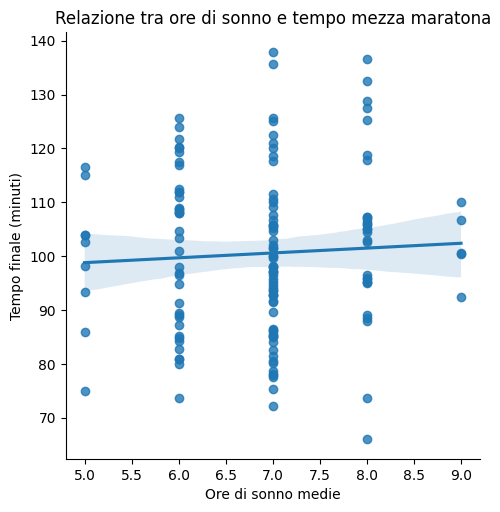

Coefficiente di correlazione: 0.055931507340495214


In [68]:
sns.lmplot(x='sleep_hour', y='hm_time_min', data=df)
plt.title('Relazione tra ore di sonno e tempo mezza maratona')
plt.xlabel('Ore di sonno medie')
plt.ylabel('Tempo finale (minuti)')
plt.show()

corr = df['sleep_hour'].corr(df['hm_time_min'])
print(f"Coefficiente di correlazione: {corr}")

Non c'è nessuna relazione diretta forte tra il sonno dell'atleta e il suo tempo finale in gara. 
Atleti con lo stesso sonno ottengono tempi molto diversi.

In [69]:
df.drop(columns=['sleep_hour'], inplace=True)

Possiamo quindi rimuovere la colonna, in modo da avere meno rumore successivamente nella fase di previsione.

### KDE - Density Plot (Group By Sex)

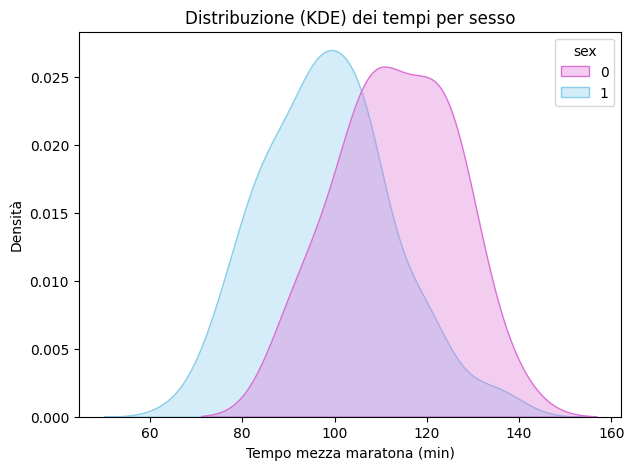

In [70]:
plt.figure(figsize=(7,5))
sns.kdeplot(
    data=df, x='hm_time_min', hue='sex',
    common_norm=False, fill=True, alpha=0.35,
    palette=['orchid', 'skyblue']
)
plt.title('Distribuzione (KDE) dei tempi per sesso')
plt.xlabel('Tempo mezza maratona (min)')
plt.ylabel('Densità')
plt.show()

###  Analisi per quartili

Prendiamo il primo (più veloci) e l'ultimo quartile (più lenti) per analizzarne le differenze.

In [71]:
q1 = df['hm_time_min'].quantile(0.25)
q3 = df['hm_time_min'].quantile(0.75)

# Creazione gruppi
df['quartile_group'] = pd.cut(
    df['hm_time_min'],
    bins=[df['hm_time_min'].min()-0.1, q1, q3, df['hm_time_min'].max()+0.1],
    labels=['Q1', 'Q2-Q3', 'Q4']
)

In [72]:
q1_df = df[df['quartile_group'] == 'Q1']
q4_df = df[df['quartile_group'] == 'Q4']

In [73]:
print("Q1 - Media Tempo Finale:", q1_df.hm_time_min.mean())
print("Q4 - Media Tempo Finale:", q4_df.hm_time_min.mean())

Q1 - Media Tempo Finale: 82.1990990990991
Q4 - Media Tempo Finale: 119.91388888888888


In [74]:
print("Q1 - Media km settimanali:", q1_df.avg_km_week.mean())
print("Q4 - Media km settimanali:", q4_df.avg_km_week.mean())


Q1 - Media km settimanali: 59.32432432432432
Q4 - Media km settimanali: 31.52777777777778


#### Numero allenamenti settimanali

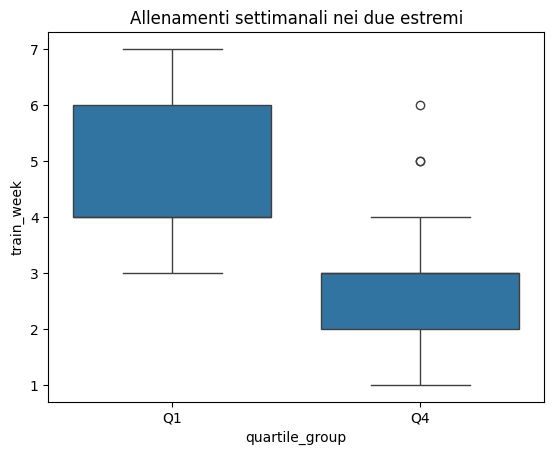

In [75]:
sns.boxplot(
    data=df[df['quartile_group'].isin(['Q1', 'Q4'])],
    x='quartile_group', y='train_week',
    order=['Q1', 'Q4']
)
plt.title('Allenamenti settimanali nei due estremi')
plt.show()

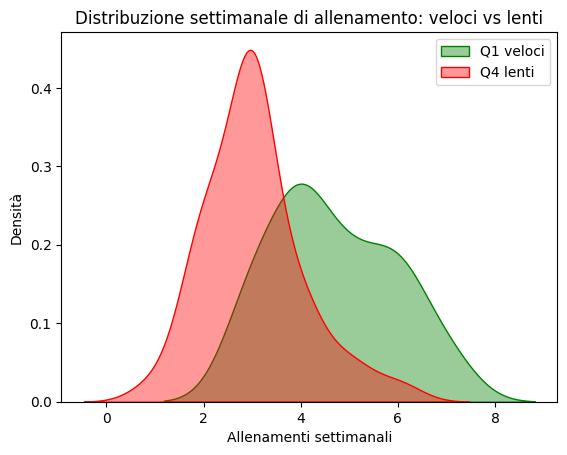

In [76]:
sns.kdeplot(data=q1_df, x='train_week', label='Q1 veloci', fill=True, alpha=0.4, color='green')
sns.kdeplot(data=q4_df, x='train_week', label='Q4 lenti', fill=True, alpha=0.4, color='red')

plt.title('Distribuzione settimanale di allenamento: veloci vs lenti')
plt.xlabel('Allenamenti settimanali')
plt.ylabel('Densità')
plt.legend()
plt.show()

#### Allenamenti di corsa Z2 settimanali

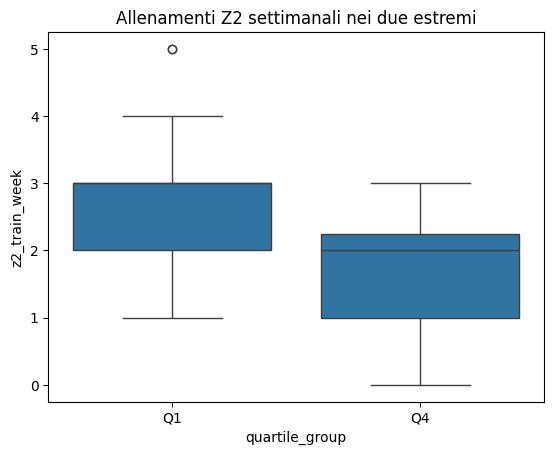

In [77]:
sns.boxplot(data=df[df['quartile_group'].isin(['Q1', 'Q4'])],
            x='quartile_group', y='z2_train_week', order=['Q1', 'Q4'])
plt.title('Allenamenti Z2 settimanali nei due estremi')
plt.show()

#### Allenamenti di potenza settimanali

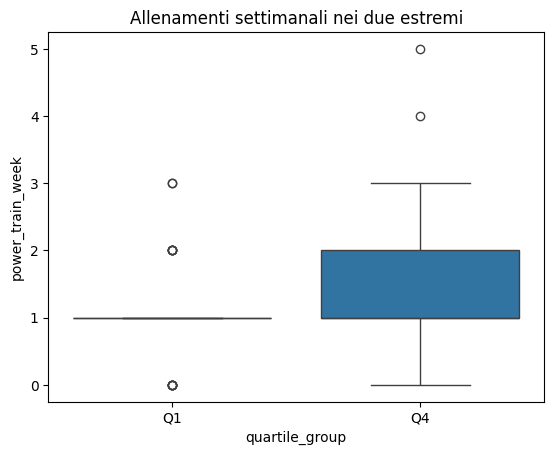

In [78]:
sns.boxplot(data=df[df['quartile_group'].isin(['Q1', 'Q4'])],
            x='quartile_group', y='power_train_week', order=['Q1', 'Q4'])
plt.title('Allenamenti settimanali nei due estremi')
plt.show()

Dal grafico si nota una differenza chiara nella frequenza di allenamento tra i due quartili presi in esame.
I runner più veloci mostrano una distribuzione centrata su 4–6 allenamenti settimanali, mentre i più lenti si concentrano intorno a 2 sedute settimanali. 
Il numero di allenamenti risulta quindi una variabile molto importante per la performance finale.

---

# Prevision

Essendo la variabile target continua, si utilizzerà l'indice R² per confrontare i vari modelli.

L'indice R² è una misura statistica che serve a valutare quanto bene un modello di regressione spiega la variabilità dei dati osservati.

Si calcola, sottraendo a 1, la somma dei quadrati dei residui (valore predetto - valore reale) diviso la somma dei quadrati totali (valore reale - valore medio).

## Splitting

In [79]:
from sklearn import model_selection

data_train, data_test = model_selection.train_test_split(df, test_size=0.2, random_state=42)

Il dataset è stato diviso con una percentuale dell'80% per il train e il restante 20% come test.

Avendo poche osservazioni, è stato deciso di non utilizzare il validation set in modo da avere più informazioni possibili nella fase di training.

In [80]:
# Train set
X_train = data_train[['age','sex','weight','height' ,'avg_km_week', 'train_years', 
                'train_week','z2_train_week', 'fartelk_train_week', 'power_train_week',
                'min_heart_rate','max_heart_rate']]

y_train = data_train['hm_time_min']


# Test set
X_test = data_test[['age','sex','weight','height','avg_km_week','train_years',
                  'train_week','z2_train_week','fartelk_train_week',
                  'power_train_week','min_heart_rate','max_heart_rate']]

y_test = data_test['hm_time_min']

In [81]:
rmse_results = []

## Linear Regression

LinearRegression fits a linear model with coefficients w = (w1, …, wp) to minimize the residual sum of squares between the observed targets in the dataset, and the targets predicted by the linear approximation.

Fonte: scikit-learn.org

In realtà, questa è una regressione multipla perchè ci sono più variabili indipendenti.

In [82]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
rmse_results.append(("LinearRegression",rmse))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"MSE  : {mse:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"MAE  : {mae:.2f}")
print(f"R²   : {r2:.4f}")




MSE  : 85.55
RMSE : 9.25
MAE  : 7.41
R²   : 0.5676


## RBF

In [83]:
from sklearn.svm import SVR
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Creazione modello SVM (kernel RBF di default)
svm_model = SVR(kernel='rbf', C=1000, gamma=0.001, epsilon=10)

# Addestramento
svm_model.fit(X_train, y_train)

# Predizioni
y_pred = svm_model.predict(X_test)

# Metriche
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
rmse_results.append(("SVM_RBF",rmse))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"MSE  : {mse:.2f}")
print(f"RMSE : {rmse:.2f} min")
print(f"MAE  : {mae:.2f} min")
print(f"R²   : {r2:.4f}")

MSE  : 139.91
RMSE : 11.83 min
MAE  : 9.25 min
R²   : 0.2928


## Pipeline con trasformazione e ricerca dei parametri ottimali su SVR (kernel RBF) 

Lo **Scaling** permette di normalizzare le feature. Molto utile in questo caso in cui le feature possono avere valori molto diversi. 

Esistono diversi tipi di scaling: RobustScaler, MinMaxScaler, StandardScaler, PowerTransformer

**GridSearchCV** è uno strumento che permette di trovare automaticamente i migliori iperparametri di un modello.

In [84]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PowerTransformer

pipe = make_pipeline(PowerTransformer(), SVR())

param_grid = {
    'svr__C': [1, 10, 100, 1000],
    'svr__gamma': [0.0001, 0.001, 0.01, 0.1, 'scale', 'auto'],
    'svr__epsilon': [0.05, 0.1, 0.5, 1, 2, 5, 10]
}

grid = GridSearchCV(pipe, param_grid, scoring='r2', cv=10, n_jobs=-1)
grid.fit(X_train, y_train)

best_model = grid.best_estimator_
print("Migliori parametri:", grid.best_params_)

y_pred = best_model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
rmse_results.append(("SVM_RBF_Tuned",rmse))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"MSE  : {mse:.2f}")
print(f"RMSE : {rmse:.2f} min")
print(f"MAE  : {mae:.2f} min")
print(f"R²   : {r2:.4f}")


Migliori parametri: {'svr__C': 1000, 'svr__epsilon': 10, 'svr__gamma': 0.001}
MSE  : 67.98
RMSE : 8.24 min
MAE  : 6.41 min
R²   : 0.6564


Epsilon è più grande del RMSE. Di conseguenza, il modello ignora gran parte delle deviazioni (underfitting).

## Random Forest

In [85]:
from sklearn.ensemble import RandomForestRegressor

# Modello Random Forest
rf_model = RandomForestRegressor(
    n_estimators=500,    # numero di alberi
    max_depth=5,      
    random_state=42,
    n_jobs=-1
)

# Addestramento
rf_model.fit(X_train, y_train)

# Predizioni
y_pred = rf_model.predict(X_test)

# Metriche
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
rmse_results.append(("RandomForest",rmse))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"MSE  : {mse:.2f}")
print(f"RMSE : {rmse:.2f} min")
print(f"MAE  : {mae:.2f} min")
print(f"R²   : {r2:.4f}")


MSE  : 122.63
RMSE : 11.07 min
MAE  : 8.18 min
R²   : 0.3801


## Gradient Boosting Regressor

In [86]:
from sklearn.ensemble import GradientBoostingRegressor

gbr = GradientBoostingRegressor(
    n_estimators=10000,
    learning_rate=0.6,
    random_state=42
)

# Addestramento
gbr.fit(X_train, y_train)

# Predizioni
y_pred_gbr = gbr.predict(X_test)

# Metriche
mse_gbr = mean_squared_error(y_test, y_pred_gbr)
rmse_gbr = np.sqrt(mse_gbr)
rmse_results.append(("GradientBoosting",rmse_gbr))
mae_gbr = mean_absolute_error(y_test, y_pred_gbr)
r2_gbr = r2_score(y_test, y_pred_gbr)

print(f"[GBR] MSE  : {mse_gbr:.2f}")
print(f"[GBR] RMSE : {rmse_gbr:.2f} min")
print(f"[GBR] MAE  : {mae_gbr:.2f} min")
print(f"[GBR] R²   : {r2_gbr:.4f}")


[GBR] MSE  : 130.69
[GBR] RMSE : 11.43 min
[GBR] MAE  : 9.08 min
[GBR] R²   : 0.3394


## XGB - eXtreme Gradient Boosting

In [87]:
import xgboost as xgb

# Creazione modello XGBoost Regressor
xgb_model = xgb.XGBRegressor(
    n_estimators=10000,       # numero di alberi
    learning_rate=0.1,     # tasso di apprendimento
    max_depth=4,            # profondità massima
    subsample=0.6,          # percentuale di campioni usati per ogni albero
    colsample_bytree=0.6,   # percentuale di feature usate per ogni albero
    random_state=42,
    n_jobs=-1
)

# Addestramento
xgb_model.fit(X_train, y_train)

# Predizioni
y_pred = xgb_model.predict(X_test)

# Metriche
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
rmse_results.append(("XGBoost",rmse))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"[XGBoost] MSE  : {mse:.2f}")
print(f"[XGBoost] RMSE : {rmse:.2f} min")
print(f"[XGBoost] MAE  : {mae:.2f} min")
print(f"[XGBoost] R²   : {r2:.4f}")

[XGBoost] MSE  : 123.36
[XGBoost] RMSE : 11.11 min
[XGBoost] MAE  : 8.23 min
[XGBoost] R²   : 0.3764


### Ridge / Lasso Regression

La regressione ridge, nota anche come regolarizzazione L2, è uno dei diversi tipi di regolarizzazione per i modelli di regressione lineare. La regolarizzazione è un metodo statistico per ridurre gli errori causati dall'overfitting dei dati di addestramento. La regressione ridge corregge specificamente la multicollinearità nell'analisi di regressione. Questo è utile quando si sviluppano modelli di machine learning con un numero elevato di parametri, in particolare se tali parametri hanno anche pesi elevati.

Fonte: IBM

In [88]:
# Ridge con scaling + CV su alpha
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import Pipeline

ridge_pipe = Pipeline([
    ("scaler", PowerTransformer()),
    ("ridge", RidgeCV(alphas=np.logspace(-3, 3, 50), cv=5, scoring="neg_mean_squared_error"))
])

ridge_pipe.fit(X_train, y_train)
y_pred_ridge = ridge_pipe.predict(X_test)

mse_ridge = mean_squared_error(y_test, y_pred_ridge)
rmse_ridge = np.sqrt(mse_ridge)
rmse_results.append(("Ridge",rmse_ridge))
mae_ridge  = mean_absolute_error(y_test, y_pred_ridge)
r2_ridge   = r2_score(y_test, y_pred_ridge)

best_alpha_ridge = ridge_pipe.named_steps["ridge"].alpha_
print(f"[Ridge] Best alpha: {best_alpha_ridge:.5f}")
print(f"[Ridge] MSE  : {mse_ridge:.2f}")
print(f"[Ridge] RMSE : {rmse_ridge:.2f} min")
print(f"[Ridge] MAE  : {mae_ridge:.2f} min")
print(f"[Ridge] R²   : {r2_ridge:.4f}")


[Ridge] Best alpha: 8.28643
[Ridge] MSE  : 66.72
[Ridge] RMSE : 8.17 min
[Ridge] MAE  : 6.55 min
[Ridge] R²   : 0.6627


La regressione lasso, nota anche come regolarizzazione L1, è una forma di regolarizzazione per i modelli di regressione lineare. La regolarizzazione è un metodo statistico per ridurre gli errori causati dall'overfitting dei dati di addestramento.

Fonte: IBM

In [89]:
# Lasso con scaling + CV su alpha
from sklearn.linear_model import LassoCV
from sklearn.pipeline import Pipeline


lasso_pipe = Pipeline([
    ("scaler", PowerTransformer()),
    ("lasso", LassoCV(alphas=np.logspace(-3, 3, 50), cv=5, random_state=42, max_iter=10000))
])

lasso_pipe.fit(X_train, y_train)
y_pred_lasso = lasso_pipe.predict(X_test)

mse_lasso = mean_squared_error(y_test, y_pred_lasso)
rmse_lasso = np.sqrt(mse_lasso)
rmse_results.append(("Lasso",rmse_lasso))
mae_lasso  = mean_absolute_error(y_test, y_pred_lasso)
r2_lasso   = r2_score(y_test, y_pred_lasso)

best_alpha_lasso = lasso_pipe.named_steps["lasso"].alpha_
print(f"[Lasso] Best alpha: {best_alpha_lasso:.5f}")
print(f"[Lasso] MSE  : {mse_lasso:.2f}")
print(f"[Lasso] RMSE : {rmse_lasso:.2f} min")
print(f"[Lasso] MAE  : {mae_lasso:.2f} min")
print(f"[Lasso] R²   : {r2_lasso:.4f}")


[Lasso] Best alpha: 0.21210
[Lasso] MSE  : 67.63
[Lasso] RMSE : 8.22 min
[Lasso] MAE  : 6.62 min
[Lasso] R²   : 0.6582


### ElasticNet

Linear Elastic Net utilizza la classe Python sklearn.linear_model.ElasticNet per stimare i modelli di regressione lineare regolarizzati per una variabile dipendente su una o più variabili indipendenti. 

La regolarizzazione combina le penalità L1 (Lasso) e L2 (Ridge). L'estensione include modalità facoltative per visualizzare i grafici di traccia per i diversi valori di alfa per un determinato rapporto L1 e per selezionare i valori del rapporto L1 e dell'iperparametro alfa in base alla convalida incrociata. 

Quando viene adattato un singolo modello o viene utilizzata la convalida incrociata per selezionare il rapporto di penalità e / o alfa, è possibile utilizzare una partizione di dati di holdout per stimare le prestazioni out - of - sample.

In [90]:
# Elastic Net con scaling + CV su alpha e l1_ratio
from sklearn.linear_model import ElasticNetCV
from sklearn.pipeline import Pipeline


enet_pipe = Pipeline([
    ("scaler", PowerTransformer()),
    ("enet", ElasticNetCV(
        alphas=np.logspace(-3, 3, 50),
        l1_ratio=[0.2, 0.5, 0.8, 0.95, 1.0],
        cv=5, random_state=42, max_iter=10000
    ))
])

enet_pipe.fit(X_train, y_train)
y_pred_enet = enet_pipe.predict(X_test)

mse_enet = mean_squared_error(y_test, y_pred_enet)
rmse_enet = np.sqrt(mse_enet)
rmse_results.append(("ElasticNet",rmse_enet))
mae_enet  = mean_absolute_error(y_test, y_pred_enet)
r2_enet   = r2_score(y_test, y_pred_enet)

best_alpha_enet = enet_pipe.named_steps["enet"].alpha_
best_l1_ratio   = enet_pipe.named_steps["enet"].l1_ratio_
print(f"[ElasticNet] Best alpha: {best_alpha_enet:.5f} | Best l1_ratio: {best_l1_ratio}")
print(f"[ElasticNet] MSE  : {mse_enet:.2f}")
print(f"[ElasticNet] RMSE : {rmse_enet:.2f} min")
print(f"[ElasticNet] MAE  : {mae_enet:.2f} min")
print(f"[ElasticNet] R²   : {r2_enet:.4f}")


[ElasticNet] Best alpha: 0.12068 | Best l1_ratio: 0.2
[ElasticNet] MSE  : 66.12
[ElasticNet] RMSE : 8.13 min
[ElasticNet] MAE  : 6.47 min
[ElasticNet] R²   : 0.6658


### Gaussian Processes 

In [91]:
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel


# Kernel: RBF + WhiteKernel per gestire rumore
kernel = 1.0 * RBF(length_scale=1.0) + WhiteKernel(noise_level=1e-2)

# Modello GPR
gpr = GaussianProcessRegressor(
    kernel=kernel,
    alpha=1e-2,              # niente rumore extra (già nel WhiteKernel)
    normalize_y=True,
    n_restarts_optimizer=5,
    random_state=42
)

# Addestramento
gpr.fit(X_train, y_train)

# Predizioni
y_pred = gpr.predict(X_test)

# Metriche
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
rmse_results.append(("GPR",rmse))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"[GPR] MSE  : {mse:.2f}")
print(f"[GPR] RMSE : {rmse:.2f}")
print(f"[GPR] MAE  : {mae:.2f}")
print(f"[GPR] R²   : {r2:.4f}")

[GPR] MSE  : 122.03
[GPR] RMSE : 11.05
[GPR] MAE  : 8.61
[GPR] R²   : 0.3832


#### Confronto RMSE tra modelli

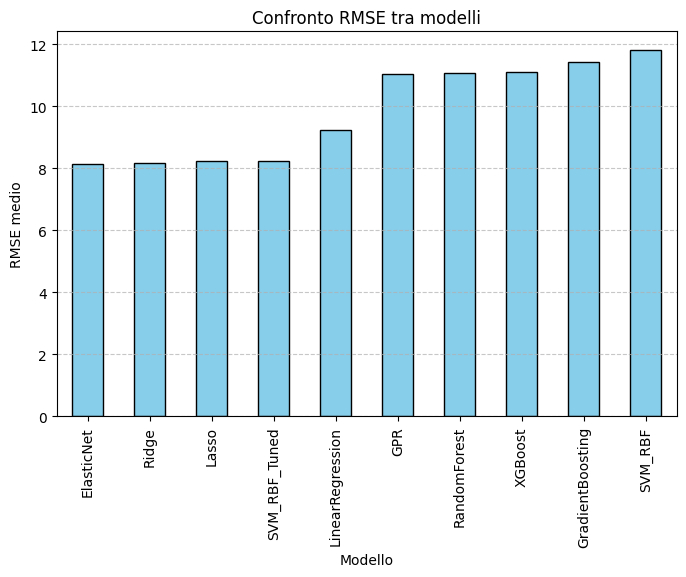

In [92]:

# Trasforma la lista di tuple in DataFrame
df = pd.DataFrame(rmse_results, columns=["Modello", "RMSE"])

# Calcola la media degli RMSE per modello
rmse_mean = df.groupby("Modello")["RMSE"].mean().sort_values()

# Grafico a barre
plt.figure(figsize=(8, 5))
rmse_mean.plot(kind="bar", color="skyblue", edgecolor="black")

plt.ylabel("RMSE medio")
plt.title("Confronto RMSE tra modelli")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()


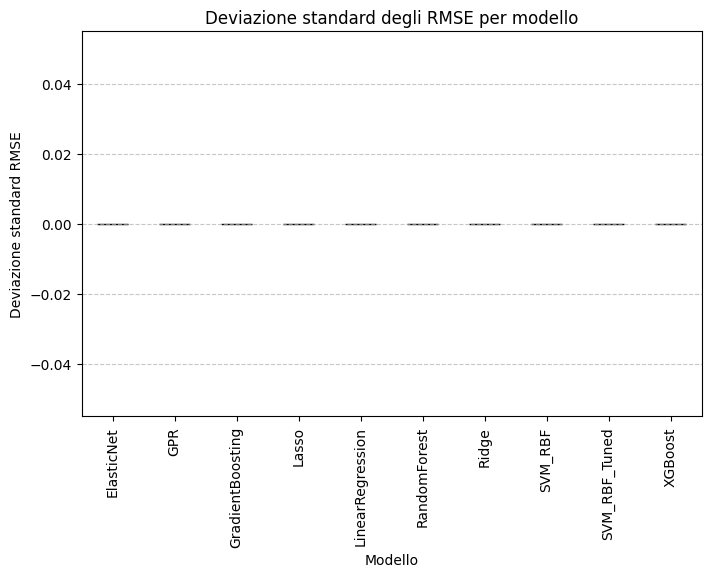

In [93]:
# Supponiamo di avere già la lista rmse_results
df = pd.DataFrame(rmse_results, columns=["Modello", "RMSE"])

# Calcola la deviazione standard per modello
rmse_std = df.groupby("Modello")["RMSE"].std().sort_values()

# Grafico a barre delle deviazioni standard
plt.figure(figsize=(8, 5))
rmse_std.plot(kind="bar", color="salmon", edgecolor="black")

plt.ylabel("Deviazione standard RMSE")
plt.title("Deviazione standard degli RMSE per modello")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.xticks(rotation=90) 
plt.show()


## Cross-Validation

In [94]:
models = ["LinearRegression", "SVR_RBF","RandomForest" ,"Ridge"]
mean_rmse = []
std_rmse = []

#### LinearRegression

In [95]:
from sklearn.model_selection import RepeatedKFold, cross_val_score

model = LinearRegression()

# 10-fold CV ripetuta 5 volte
cv = RepeatedKFold(n_splits=10, n_repeats=5, random_state=42)

scores = cross_val_score(model, X_train, y_train,
                         scoring="neg_root_mean_squared_error",
                         cv=cv)

rmse_values = -scores  # cross_val_score restituisce valori negativi
print("RMSE per ogni fold:", rmse_values)
print("Media RMSE:", np.mean(rmse_values))
mean_rmse.append(np.mean(rmse_values))
print("Deviazione standard:", np.std(rmse_values, ddof=1))
std_rmse.append(np.std(rmse_values, ddof=1))


RMSE per ogni fold: [ 8.76727715  9.33517945 11.17581488 14.05227717 10.81091008  5.65425107
 11.95101063 12.36818469 15.265992    6.92596083 11.53126557 11.5810447
  8.65711571 13.75073381  6.94403669 12.90621087  6.96938565 12.45566292
 11.70612217 11.63364204  6.21703754  9.7912338  10.24533394 13.57762634
  8.52744985 13.67563304  7.44409666 11.43585813 13.50294428 11.48942634
  7.62246285  7.70478995  8.1696777  11.65486544  8.95801728 12.64926339
  9.81081146 11.3386468  11.78829099 15.84687263 10.44557227  7.7154726
 11.9613958  11.70168521 13.06769696  8.72777001 11.74198612 10.31903873
 10.2586178  11.86209887]
Media RMSE: 10.673875017127523
Deviazione standard: 2.40176361001027


#### SVR - RBF

In [96]:

# Modello SVR con kernel RBF (qui puoi mettere i tuoi parametri ottimizzati)
model = SVR(kernel="rbf", C=1000, gamma=0.001, epsilon=10)

# 10-fold CV ripetuta 5 volte
cv = RepeatedKFold(n_splits=10, n_repeats=5, random_state=42)

# cross_val_score restituisce valori negativi per convenzione (errori)
scores = cross_val_score(model, X_train, y_train,
                         scoring="neg_root_mean_squared_error",
                         cv=cv, n_jobs=-1)

# Invertiamo il segno → valori RMSE veri
rmse_values = -scores  

print("RMSE per ogni fold:", rmse_values)
print("Media RMSE:", np.mean(rmse_values))
mean_rmse.append(np.mean(rmse_values))
print("Deviazione standard:", np.std(rmse_values, ddof=1))
std_rmse.append(np.std(rmse_values, ddof=1))


RMSE per ogni fold: [ 9.74040752  9.58212295 13.59539223 14.10383227 12.63995869  9.03917382
 13.05714023 11.15212498 17.17607371 10.37371339 10.3612753  10.36572189
  9.78118805 13.12076067 11.66720395 16.30928163  6.56216969 14.20404737
  9.26031607 14.7271554   9.08257773 11.01268993 11.25611131 17.4381771
  8.99770488 15.17041494  8.59735642 10.19753577 14.43476057 14.34654017
  8.28234367 10.03864719  7.69633919 15.5460215  13.45486901 11.59370056
  6.42720578 11.04601666 14.00537022 17.84974007 10.3800126  17.06224696
 14.44539116 11.07242633 13.05935474 13.54368647 12.55268424  9.07796226
  8.98128027 11.23423464]
Media RMSE: 11.8940492423092
Deviazione standard: 2.859747132363333


In [97]:
rf_model = RandomForestRegressor(
    n_estimators=500,
    max_depth=None,
    random_state=42,
    n_jobs=-1
)

# Cross-validation ripetuta
cv = RepeatedKFold(n_splits=10, n_repeats=5, random_state=42)

scores = cross_val_score(rf_model, X_train, y_train,
                         scoring="neg_root_mean_squared_error",
                         cv=cv, n_jobs=-1)

rmse_values_rf = -scores
print("Random Forest - RMSE medio:", np.mean(rmse_values_rf))
mean_rmse.append(np.mean(rmse_values_rf))
print("Random Forest - Dev std:", np.std(rmse_values_rf, ddof=1))
std_rmse.append(np.std(rmse_values_rf, ddof=1))

Random Forest - RMSE medio: 11.284829292067107
Random Forest - Dev std: 2.9766896608198232


In [98]:
from sklearn.linear_model import Ridge

model = Ridge(alpha=1.0, random_state=42)

# 10-fold CV ripetuta 5 volte
cv = RepeatedKFold(n_splits=10, n_repeats=5, random_state=42)

# cross_val_score restituisce valori negativi (errore) → li invertiamo
scores = cross_val_score(model, X_train, y_train,
                         scoring="neg_root_mean_squared_error",
                         cv=cv, n_jobs=-1)

rmse_values = -scores

print("RMSE per ogni fold:", rmse_values)
print("Media RMSE:", np.mean(rmse_values))
mean_rmse.append(np.mean(rmse_values))
print("Deviazione standard:", np.std(rmse_values, ddof=1))
std_rmse.append(np.std(rmse_values, ddof=1))

RMSE per ogni fold: [ 8.20970325  9.04385318 11.24132199 14.08886003 11.03567987  5.53776003
 11.95744572 11.9910155  15.57327177  6.70996278 11.56835344 11.61580927
  8.20136632 13.82774462  7.0059165  13.16195143  6.91995661 12.50583298
 11.6403904  11.19984093  6.12140444  9.80982018 10.20822432 13.68743128
  8.0415361  13.76533542  7.37480329 11.50379198 13.69957621 11.5280155
  7.56109197  7.83619283  7.92495983 11.60042623  8.55609949 12.67554782
  9.83470664 11.26225979 11.95801306 16.07098211 10.49364111  7.19890992
 12.32931429 11.47471065 12.72998354  8.97689989 11.89500861 10.18006397
 10.25151774 11.92015361]
Media RMSE: 10.630129168799776
Deviazione standard: 2.5052256642249207


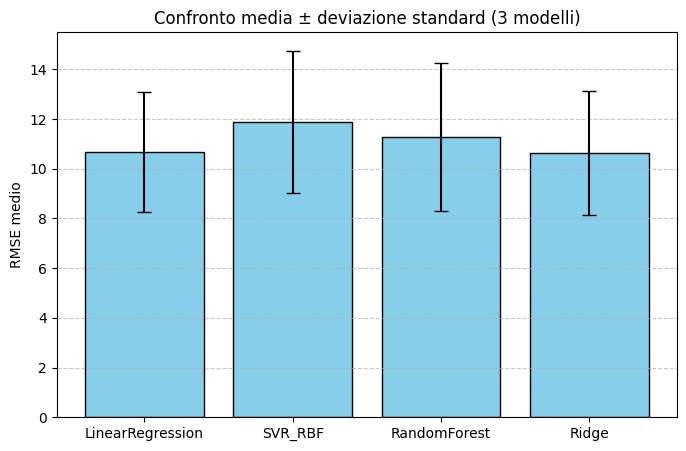

In [99]:
plt.figure(figsize=(8,5))
plt.bar(models, mean_rmse, yerr=std_rmse, capsize=5, color="skyblue", edgecolor="black")

plt.ylabel("RMSE medio")
plt.title("Confronto media ± deviazione standard (3 modelli)")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()

## Hyperparameter Tuning

Degree=1 | RMSE=8.9539 | MAE=6.8932 | R2=0.5948
Degree=2 | RMSE=14.4716 | MAE=11.7004 | R2=-0.0586
Degree=3 | RMSE=14.0181 | MAE=11.4660 | R2=0.0067
Degree=4 | RMSE=14.9176 | MAE=12.1001 | R2=-0.1248
Degree=5 | RMSE=14.9370 | MAE=12.1127 | R2=-0.1278


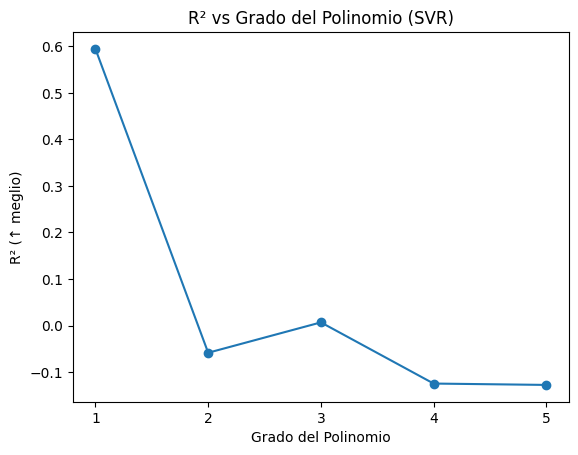

In [100]:
from sklearn.pipeline import Pipeline
from sklearn import svm

gradi = range(1, 6)
rmse_list, mae_list, r2_list = [], [], []

for d in gradi:
    # Pipeline con scaling + SVR polinomiale
    modelSVR = Pipeline([
        ("scaler", StandardScaler()),
        ("svr", svm.SVR(C=100, kernel="poly", degree=d, epsilon=10, gamma=0.01))
    ])

    modelSVR.fit(X_train, y_train)
    y_pred = modelSVR.predict(X_test)

    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    mae  = mean_absolute_error(y_test, y_pred)
    r2   = r2_score(y_test, y_pred)

    rmse_list.append(rmse)
    mae_list.append(mae)
    r2_list.append(r2)

    print(f"Degree={d} | RMSE={rmse:.4f} | MAE={mae:.4f} | R2={r2:.4f}")

plt.plot(gradi, r2_list, marker='o')
plt.title('R² vs Grado del Polinomio (SVR)')
plt.xlabel('Grado del Polinomio')
plt.ylabel('R² (↑ meglio)')
plt.xticks(gradi)
plt.show()

Aumentando il grado del polinomio, il modello diventa sempre più flessibile e curvo, creando un andamento che non riflette la realtà, peggiorando le previsioni.
Per questo l'indice R2 diminuisce.